# Figure 5

In [1]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_loo_comparison,
    load_ddm_posterior,
    DATASET_LABELS,
)
import numpy as np
import matplotlib.pyplot as plt

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]
PUPIL_MODEL = "HDDM_Base_Lag1-stpdrift_Pupil"
FULL_MODEL = "HDDM_Base_Lag1-stpdrift_Pupil_stpdrift"

### Helper functions

In [2]:
BAR_COLOR = "#4C72B0"

ELPD_MODEL_ORDER = [
    ("HDDM_Base_Lag1-stpdrift_Pupil_stp",      "Pupil ->\nStp-CH"),
    ("HDDM_Base_Lag1-stpdrift_Pupil_drift",    "Pupil ->\nDrift-CH"),
    ("HDDM_Base_Lag1-stpdrift_Pupil_stpdrift", "Pupil ->\nStp-Drift-CH"),
]


def plot_elpd_improvement_panel(ax, dataset, show_ylabel=False):
    """Bars: elpd_loo(variant) - elpd_loo(PUPIL_MODEL) for each mechanism
    variant, i.e. how much better each pupil-modulation model fits than the
    plain Pupil model. No error bars -- the LOO table's own `dse` is the SE
    relative to whichever model ranks best, not specifically to PUPIL_MODEL
    (see figure3.ipynb's equivalent draft cell for the same reasoning)."""
    loo = load_loo_comparison(dataset, group_name="mechanisms_arousal").set_index("model")["elpd_loo"]
    baseline_elpd = loo[PUPIL_MODEL]
    diffs = [loo[m] - baseline_elpd for m, _ in ELPD_MODEL_ORDER]

    x_pos = np.arange(len(ELPD_MODEL_ORDER))
    ax.bar(x_pos, diffs, color=BAR_COLOR, width=0.6, zorder=3)
    ax.axhline(0, color="black", linestyle="--", linewidth=1.5, zorder=2)

    ax.set_xticks(x_pos)
    ax.set_xticklabels([label for _, label in ELPD_MODEL_ORDER])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_title(DATASET_LABELS.get(dataset, dataset))
    if show_ylabel:
        ax.set_ylabel("ELPD improvement\nover Pupil model")


def group_samples(posterior, param):
    return np.asarray(posterior[param]).flatten()


def plot_posterior_histogram_panel(ax, samples, color, show_ylabel=False,
                                   xlabel=None, ylabel_text=None):
    """Group-level posterior sample histogram for one DDM parameter, with a
    dashed reference line at 0 (the no-effect null)."""
    ax.hist(samples, bins=60, color=color, alpha=0.55, linewidth=0.8, density=False)
    ax.hist(samples, bins=60, histtype="step", color="black", linewidth=1.5)
    ax.axvline(0, color="black", linestyle="--", linewidth=1.5, zorder=4)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if show_ylabel:
        ax.set_ylabel(f"{ylabel_text}\nSample Counts")
    if xlabel:
        ax.set_xlabel(f"{xlabel}\n")

### 3x3 figure: ELPD improvement and pupil-modulation posteriors
Columns = datasets. Row 1: `elpd_loo` improvement of each pupil-modulation
mechanism variant over the plain Pupil model. Row 2: group-level posterior
of `z_choice_prev1:pupil` (pupil modulation of the starting-point bias),
from the full Stp-Drift-CH model. Row 3: group-level posterior of
`v_choice_prev1:pupil` (pupil modulation of the drift bias), same model.

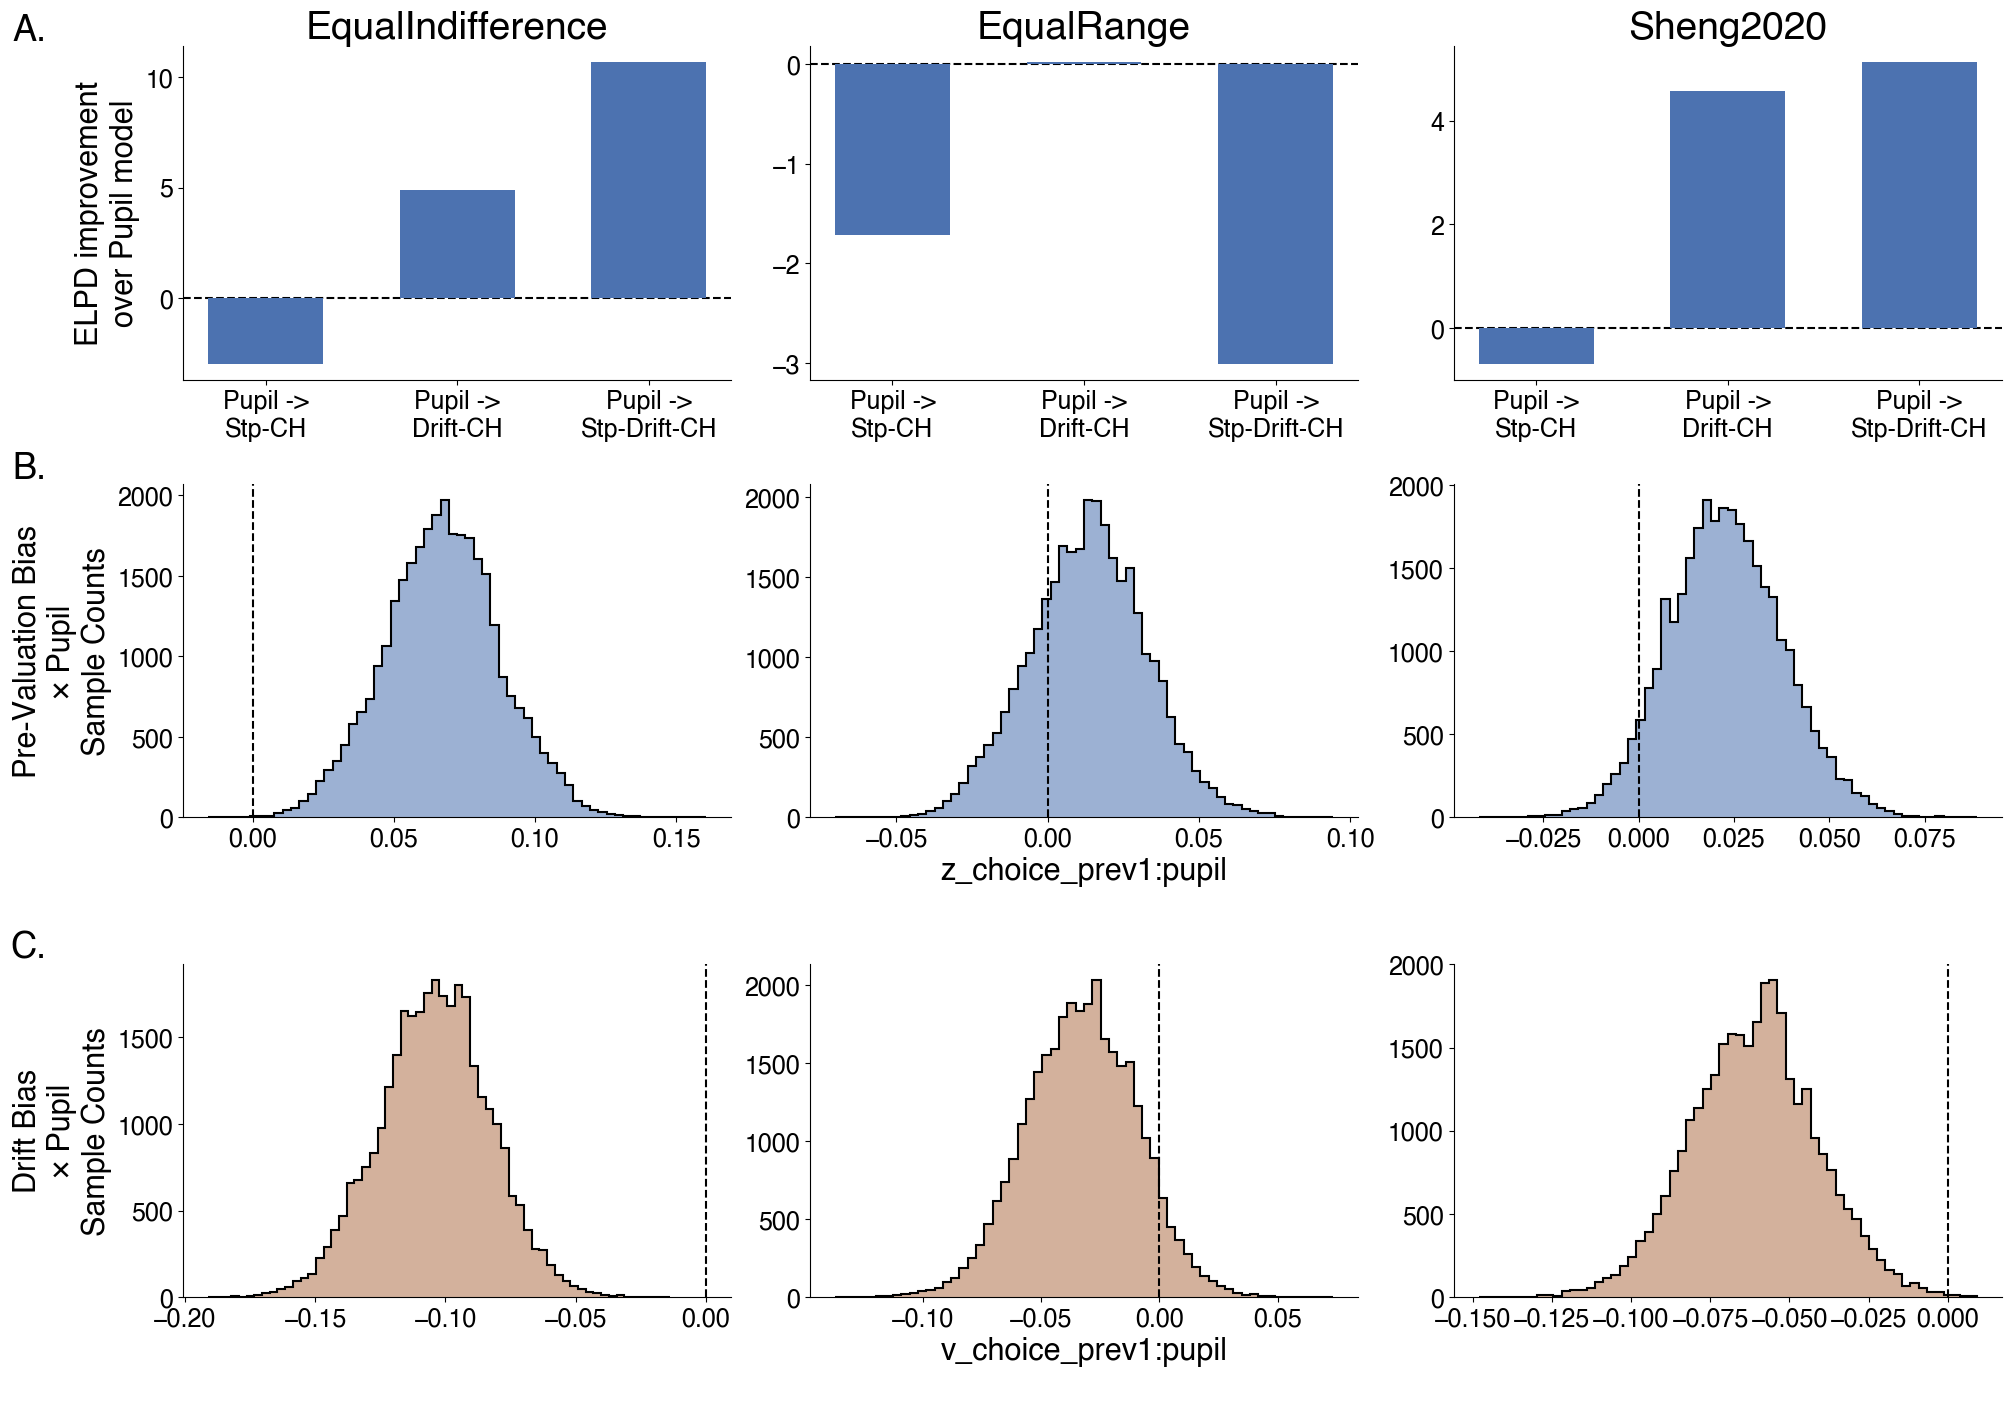

In [3]:
Z_HIST_COLOR = "#4C72B0"
V_HIST_COLOR = "#B0724C"

posteriors = {ds: load_ddm_posterior(FULL_MODEL, ds) for ds in DATASETS}

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(20, 14), layout="constrained")

# --- Row 1: ELPD improvement over the Pupil model ---
for col, ds in enumerate(DATASETS):
    plot_elpd_improvement_panel(axes[0, col], ds, show_ylabel=(col == 0))

# --- Row 2: z_choice_prev1:pupil posterior ---
for col, ds in enumerate(DATASETS):
    samples = group_samples(posteriors[ds], "z_choice_prev1:pupil")
    plot_posterior_histogram_panel(
        axes[1, col], samples, Z_HIST_COLOR, show_ylabel=(col == 0),
        xlabel="z_choice_prev1:pupil" if col == 1 else None,
        ylabel_text="Pre-Valuation Bias\n× Pupil",
    )

# --- Row 3: v_choice_prev1:pupil posterior ---
for col, ds in enumerate(DATASETS):
    samples = group_samples(posteriors[ds], "v_choice_prev1:pupil")
    plot_posterior_histogram_panel(
        axes[2, col], samples, V_HIST_COLOR, show_ylabel=(col == 0),
        xlabel="v_choice_prev1:pupil" if col == 1 else None,
        ylabel_text="Drift Bias\n× Pupil",
    )

# Row labels, placed just outside the top-left corner of each row's
# leftmost panel (same convention as figure1.ipynb's "A."/"B."/"C.")
axes[0, 0].text(-0.25, 1.1, "A.", transform=axes[0, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")
axes[1, 0].text(-0.25, 1.1, "B.", transform=axes[1, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")
axes[2, 0].text(-0.25, 1.1, "C.", transform=axes[2, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")

fig.savefig("saved/figure5.svg", dpi=300, bbox_inches="tight")
plt.show()